# 01. Создаём признаки из истории продаж

**Предварительная задача:** в начале дня `t` предсказать сумму `quantity` за этот день для пары склад × артикул. Используем продажи и остатки не позднее `t−1`.

Отсутствие строки продаж после появления пары считаем нулевой наблюдаемой продажей. Это не доказательство отсутствия спроса: продажи ограничены наличием товара. Пары начинаются с первого появления в любом исходном файле; будущий ассортимент не достраиваем в прошлое.

Сплит: последние 28 дней — тест, предыдущие 28 — валидация. Это последовательные прогнозы на один день: при прогнозе следующего дня уже известны реальные продажи предыдущего дня, включая дни валидации/теста. Для прогноза сразу на 28 дней от одной даты такой протокол применять нельзя.

## Что именно добавляем

FE (feature engineering) — создание признаков из исходных данных. **Базовая версия модели** получает пять исходных категорий: склад, артикул, два уровня категории и характеристику. **Версия с FE** получает те же поля, а дополнительно — календарь, прошлые продажи и остатки, общие продажи склада/товара и три явных сочетания категорий.

Лаг — значение несколько дней назад. Скользящее окно — среднее или другая статистика за последние несколько дней. Cross-признак — объединённая категория, например «товар × склад». Полное описание каждого входа — в [FEATURES.md](FEATURES.md). Слово «без FE» не означает отсутствие всех входов: это исходные поля без созданных здесь дополнительных признаков.

Таблица с полным рядом дней называется дневной панелью. Она нужна обеим версиям модели, чтобы одинаково учитывать дни без продаж. Train — период обучения, validation — следующий период выбора настроек, test — последний период итоговой проверки.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/datasets').is_dir())

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from features.catalog import LABELS, GROUP_LABELS, MODEL_LABELS, feature_label, identifier_label, display_ru
plt.rcParams.update({'date.autoformatter.month':'%m.%Y','date.autoformatter.day':'%d.%m',
                     'date.autoformatter.year':'%Y'})

RAW = ROOT / 'docs/datasets'
PROCESSED = ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 80)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

OUT=ROOT/'data/artifacts/features'
OUT.mkdir(parents=True,exist_ok=True)
KEY=['date','warehouse_name','article']
stock_daily=pd.read_parquet(PROCESSED/'stock_daily.parquet')
sales_daily=pd.read_parquet(PROCESSED/'sales_daily.parquet')
meta=pd.read_parquet(PROCESSED/'article_metadata.parquet')
DATE_MIN=sales_daily.date.min()
DATE_MAX=sales_daily.date.max()
TEST_START=DATE_MAX-pd.Timedelta(days=27)
VALID_START=TEST_START-pd.Timedelta(days=28)
TRAIN_END=VALID_START-pd.Timedelta(days=1)
print(f'Обучение: {DATE_MIN.date()} — {TRAIN_END.date()}')
print(f'Валидация: {VALID_START.date()} — {(TEST_START-pd.Timedelta(days=1)).date()}')
print(f'Тест: {TEST_START.date()} — {DATE_MAX.date()}')

Обучение: 2024-01-01 — 2026-06-05
Валидация: 2026-06-06 — 2026-07-03
Тест: 2026-07-04 — 2026-07-31


## Полная временная шкала для каждой наблюдаемой пары

В сырых продажах нет нулей, поэтому обучение только на записанных строках завысит прогноз. Достраиваем пропущенные дни с нулём. Остатки не заполняем вперёд: пропуск остаётся отдельным сигналом. Для конфликтующих остатков используем среднее и разброс; корректность этого допущения нужно уточнить у организаторов.

In [2]:
first_seen=(pd.concat([stock_daily[KEY],sales_daily[KEY]],ignore_index=True)
            .groupby(['warehouse_name','article'],observed=True).date.min().rename('first_seen').reset_index())
first_seen=first_seen.sort_values(['warehouse_name','article']).reset_index(drop=True)
first_seen['pair_id']=np.arange(len(first_seen),dtype='int32')
first_seen['start']=first_seen.first_seen.clip(lower=DATE_MIN)
lengths=(DATE_MAX-first_seen.start).dt.days.to_numpy()+1
pair_id=np.repeat(first_seen.pair_id.to_numpy(),lengths)
dates=np.repeat(first_seen.start.to_numpy(dtype='datetime64[ns]'),lengths)+np.concatenate([np.arange(n,dtype='timedelta64[D]') for n in lengths])
panel=pd.DataFrame({'pair_id':pair_id,'date':dates})
panel=panel.merge(first_seen[['pair_id','warehouse_name','article','first_seen']],on='pair_id',how='left',validate='many_to_one')
panel=panel.merge(sales_daily,on=KEY,how='left',validate='one_to_one')
panel['quantity']=panel.quantity.fillna(0).astype('float32')
panel=panel.merge(stock_daily,on=KEY,how='left',validate='one_to_one')
panel=panel.sort_values(['pair_id','date']).reset_index(drop=True)
assert not panel.duplicated(['pair_id','date']).any()
assert panel.groupby('pair_id',sort=False).date.diff().dropna().eq(pd.Timedelta(days=1)).all()
assert panel.quantity.ge(0).all()
print(f'{len(panel):,} строк; {len(first_seen):,} пар; доля нулевых продаж {panel.quantity.eq(0).mean():.1%}')
# Метаданные товара используем лишь после даты его первой продажи.
panel=panel.merge(meta,on='article',how='left',validate='many_to_one')
known=panel.date.gt(panel.metadata_available_from)
CATEGORICAL=['warehouse_name','article','category_lvl_1','category_lvl_2','characteristic']
for c in CATEGORICAL:
    panel[c]=panel[c].astype('string').fillna('__MISSING__')
for c in ['category_lvl_1','category_lvl_2','characteristic']:
    panel.loc[~known,c]='__UNKNOWN_AT_DATE__'
panel['metadata_known']=known.astype('int8')

6,616,681 строк; 8,778 пар; доля нулевых продаж 85.3%


## Временные признаки

Календарь известен заранее. Лаги берём на 1, 7, 14 и 28 дней; средние, разброс и долю ненулевых продаж — за прошлые 7/28 дней. Все окна заканчиваются на `t−1`. Отдельно сохраняем возраст пары и признаки неполной истории.

In [3]:
CALENDAR=['dow','month','day_of_month','day_of_year','week_of_year','year','is_weekend','dow_sin','dow_cos','month_sin','month_cos','pair_age_days','metadata_known']
panel['dow']=panel.date.dt.dayofweek.astype('int8')
panel['month']=panel.date.dt.month.astype('int8')
panel['day_of_month']=panel.date.dt.day.astype('int8')
panel['day_of_year']=panel.date.dt.dayofyear.astype('int16')
panel['week_of_year']=panel.date.dt.isocalendar().week.astype('int16')
panel['year']=panel.date.dt.year.astype('int16')
panel['is_weekend']=panel.dow.ge(5).astype('int8')
panel['dow_sin']=np.sin(2*np.pi*panel.dow/7).astype('float32')
panel['dow_cos']=np.cos(2*np.pi*panel.dow/7).astype('float32')
panel['month_sin']=np.sin(2*np.pi*(panel.month-1)/12).astype('float32')
panel['month_cos']=np.cos(2*np.pi*(panel.month-1)/12).astype('float32')
panel['pair_age_days']=(panel.date-panel.first_seen).dt.days.astype('int16')
group=panel.groupby('pair_id',sort=False).quantity
HISTORY=[]
for lag in [1,7,14,28]:
    col=f'qty_lag_{lag}'
    panel[col]=group.shift(lag).astype('float32'); HISTORY.append(col)
lagged=panel.qty_lag_1
for window in [7,28]:
    rolling=lagged.groupby(panel.pair_id,sort=False).rolling(window,min_periods=1)
    for stat in ['mean','std','max']:
        col=f'qty_roll_{stat}_{window}'
        panel[col]=getattr(rolling,stat)().to_numpy(dtype='float32'); HISTORY.append(col)
    col=f'qty_nonzero_share_{window}'
    nonzero=lagged.gt(0).astype('float32').where(lagged.notna())
    panel[col]=nonzero.groupby(panel.pair_id,sort=False).rolling(window,min_periods=1).mean().to_numpy(dtype='float32')
    HISTORY.append(col)
panel['history_missing']=panel.qty_lag_1.isna().astype('int8')
panel['qty_trend_7_28']=(panel.qty_roll_mean_7/(panel.qty_roll_mean_28+1)).astype('float32')
HISTORY+=['history_missing','qty_trend_7_28']
# Контроль на одной паре: пересчитываем лаги и rolling независимо.
example_id=int(panel.pair_id.value_counts().index[0])
check=panel.loc[panel.pair_id.eq(example_id)]
np.testing.assert_allclose(check.qty_lag_1,check.quantity.shift(1),equal_nan=True)
np.testing.assert_allclose(check.qty_roll_mean_7,check.quantity.shift(1).rolling(7,min_periods=1).mean(),equal_nan=True,rtol=1e-6)
print('Проверены порядок дней, лаг 1 и сдвиг окна 7 дней.')

Проверены порядок дней, лаг 1 и сдвиг окна 7 дней.


## Остатки и история на уровне склада / артикула

Вчерашний остаток и число исходных записей помогают учитывать наличие и неоднозначность источника. Общая история артикула и склада даёт контекст редким парам. Эти агрегаты тоже сдвинуты на день. Отношения — обычные cross-фичи между историческими величинами.

Агрегат — сумма продаж по более крупной сущности: например, по всем складам для одного артикула. Отношение двух прошлых величин — числовое взаимодействие; оно отличается от объединённой категории, но тоже позволяет модели учитывать сочетание сигналов.

In [4]:
STOCK=[]
for source in ['stock_mean','stock_min','stock_max','stock_records']:
    col=source+'_lag_1'
    panel[col]=panel.groupby('pair_id',sort=False)[source].shift(1).astype('float32'); STOCK.append(col)
panel['stock_missing_lag_1']=panel.stock_mean_lag_1.isna().astype('int8')
panel['stock_spread_lag_1']=(panel.stock_max_lag_1-panel.stock_min_lag_1).astype('float32')
panel['stock_nonpositive_lag_1']=panel.stock_mean_lag_1.le(0).astype('int8')
panel['stock_cover_7']=(panel.stock_mean_lag_1/(1+panel.qty_roll_mean_7)).astype('float32')
panel['sell_to_stock_lag_1']=(panel.qty_lag_1/(1+panel.stock_mean_lag_1.clip(lower=0))).astype('float32')
STOCK+=['stock_missing_lag_1','stock_spread_lag_1','stock_nonpositive_lag_1','stock_cover_7','sell_to_stock_lag_1']
AGGREGATE=[]
for dimension,prefix in [('warehouse_name','warehouse'),('article','article')]:
    totals=sales_daily.groupby([dimension,'date'],observed=True).quantity.sum()
    idx=pd.MultiIndex.from_product([panel[dimension].unique(),pd.date_range(DATE_MIN,DATE_MAX)],names=[dimension,'date'])
    totals=totals.reindex(idx,fill_value=0).reset_index().sort_values([dimension,'date']).reset_index(drop=True)
    grouped=totals.groupby(dimension,sort=False).quantity
    cols=[]
    for lag in [1,7]:
        col=f'{prefix}_qty_lag_{lag}'
        totals[col]=grouped.shift(lag).astype('float32'); cols.append(col)
    col=f'{prefix}_qty_roll_mean_7'
    totals[col]=totals[cols[0]].groupby(totals[dimension],sort=False).rolling(7,min_periods=1).mean().to_numpy(dtype='float32')
    cols.append(col); AGGREGATE+=cols
    panel=panel.merge(totals[[dimension,'date',*cols]],on=[dimension,'date'],how='left',validate='many_to_one')
CROSSES=['article_warehouse','article_dow','warehouse_dow']
panel['article_warehouse']=panel.article+'|'+panel.warehouse_name
panel['article_dow']=panel.article+'|'+panel.dow.astype('string')
panel['warehouse_dow']=panel.warehouse_name+'|'+panel.dow.astype('string')
for c in CATEGORICAL+CROSSES: panel[c]=panel[c].astype('category')

## Сохранение выборок и проверка сплита

Сначала делим по датам, затем выбираем до 600 тыс. train-строк с фиксированным seed. Validation/test сохраняем полностью, включая новые пары и короткие истории. До обучения любые медианы, масштабы и словари категорий считаются только по train.

Первые 28 календарных дней всей таблицы — прогрев для длинных лагов. Новые пары, появившиеся позже, сохраняются в обучении с неполной историей. Идентификаторы строк и даты нужны для проверки, но не подаются моделям как числовые признаки.

Первый день наблюдения новой пары используем только для истории. Прогноз оцениваем со следующего дня: кандидат должен быть известен к концу `t−1`, иначе сам отбор строк раскроет будущий ассортимент.

In [5]:
NUMERIC=CALENDAR+HISTORY+STOCK+AGGREGATE
FEATURES=CATEGORICAL+CROSSES+NUMERIC
assert len(FEATURES)==len(set(FEATURES))
assert not set(['quantity','stock_mean','stock_min','stock_max','stock_records','date','metadata_available_from']) & set(FEATURES)
assert not np.isinf(panel[NUMERIC].to_numpy(dtype='float32')).any()
keep=['date','pair_id','quantity',*FEATURES]
eligible=panel.pair_age_days.ge(1)
train_mask=eligible & panel.date.lt(VALID_START) & panel.date.ge(DATE_MIN+pd.Timedelta(days=28))
valid_mask=eligible & panel.date.ge(VALID_START)&panel.date.lt(TEST_START)
test_mask=eligible & panel.date.ge(TEST_START)
train_pool_rows=int(train_mask.sum())
train=panel.loc[train_mask,keep].sample(n=min(600_000,train_pool_rows),random_state=SEED).sort_values(['date','pair_id']).reset_index(drop=True)
valid=panel.loc[valid_mask,keep].reset_index(drop=True)
test=panel.loc[test_mask,keep].reset_index(drop=True)
assert train.date.max()<valid.date.min() and valid.date.max()<test.date.min()
for name,df in [('train',train),('valid',valid),('test',test)]:
    assert not df.duplicated(['date','pair_id']).any()
    # Удаляем из pandas category неиспользуемые уровни: словарь модели строится лишь по train.
    for c in CATEGORICAL+CROSSES: df[c]=df[c].cat.remove_unused_categories()
    df.to_parquet(PROCESSED/f'{name}.parquet',index=False)
summary=pd.DataFrame([{'split':name,'rows':len(df),'date_min':str(df.date.min().date()),'date_max':str(df.date.max().date()),
                      'zero_share':df.quantity.eq(0).mean(),'mean_quantity':df.quantity.mean(),
                      'short_history_share':df.pair_age_days.lt(28).mean()} for name,df in [('train',train),('valid',valid),('test',test)]])
summary.to_csv(OUT/'split_summary.csv',index=False)
display_ru(summary)
manifest={'seed':SEED,'target':'daily quantity at warehouse × article','protocol':'rolling one-day-ahead; actual observations through t-1',
          'panel_rows':len(panel),'eligible_rows':int(eligible.sum()),'pairs':len(first_seen),
          'train_pool_rows':train_pool_rows,'train_sample_rows':len(train),'train_end':str(TRAIN_END.date()),
          'valid_start':str(VALID_START.date()),'test_start':str(TEST_START.date()),'test_end':str(DATE_MAX.date()),
          'categorical':CATEGORICAL,'crosses':CROSSES,'numeric':NUMERIC,
          'groups':{'calendar':CALENDAR,'history':HISTORY,'stock':STOCK,'aggregate':AGGREGATE},
          'assumptions':['missing sale after pair introduction = zero observed sales','stock duplicates: mean/min/max/count',
                         'stock from t-1 assumed available at forecast time','article metadata available strictly after first sale'],
          'candidate_rule':'only pairs first observed before forecast day',
          'source_files':{p.name:p.stat().st_size for p in RAW.glob('*.csv')}}
manifest['feature_sets']={'base':{'categorical':CATEGORICAL,'numeric':[]},'fe':{'categorical':CATEGORICAL+CROSSES,'numeric':NUMERIC}}
(OUT/'feature_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
(PROCESSED/'feature_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))

,Период,Число строк,Первая дата,Последняя дата,Доля нулевых продаж,Средние продажи,Доля пар моложе 28 дней
0,Обучение,600000,2024-01-29,2026-06-05,0.857015,0.266422,0.029257
1,Валидация,245758,2026-06-06,2026-07-03,0.821267,0.381107,0.000305
2,Тест,245784,2026-07-04,2026-07-31,0.818361,0.399721,0.000094


4692

## Как выглядят построенные признаки

Показываем одну длинную историю и пропуски по группам фичей. Числовые взаимодействия уже включены в таблицу, а DCN дополнительно учит взаимодействия между обучаемые числовые представления категорий и числовыми признаками.

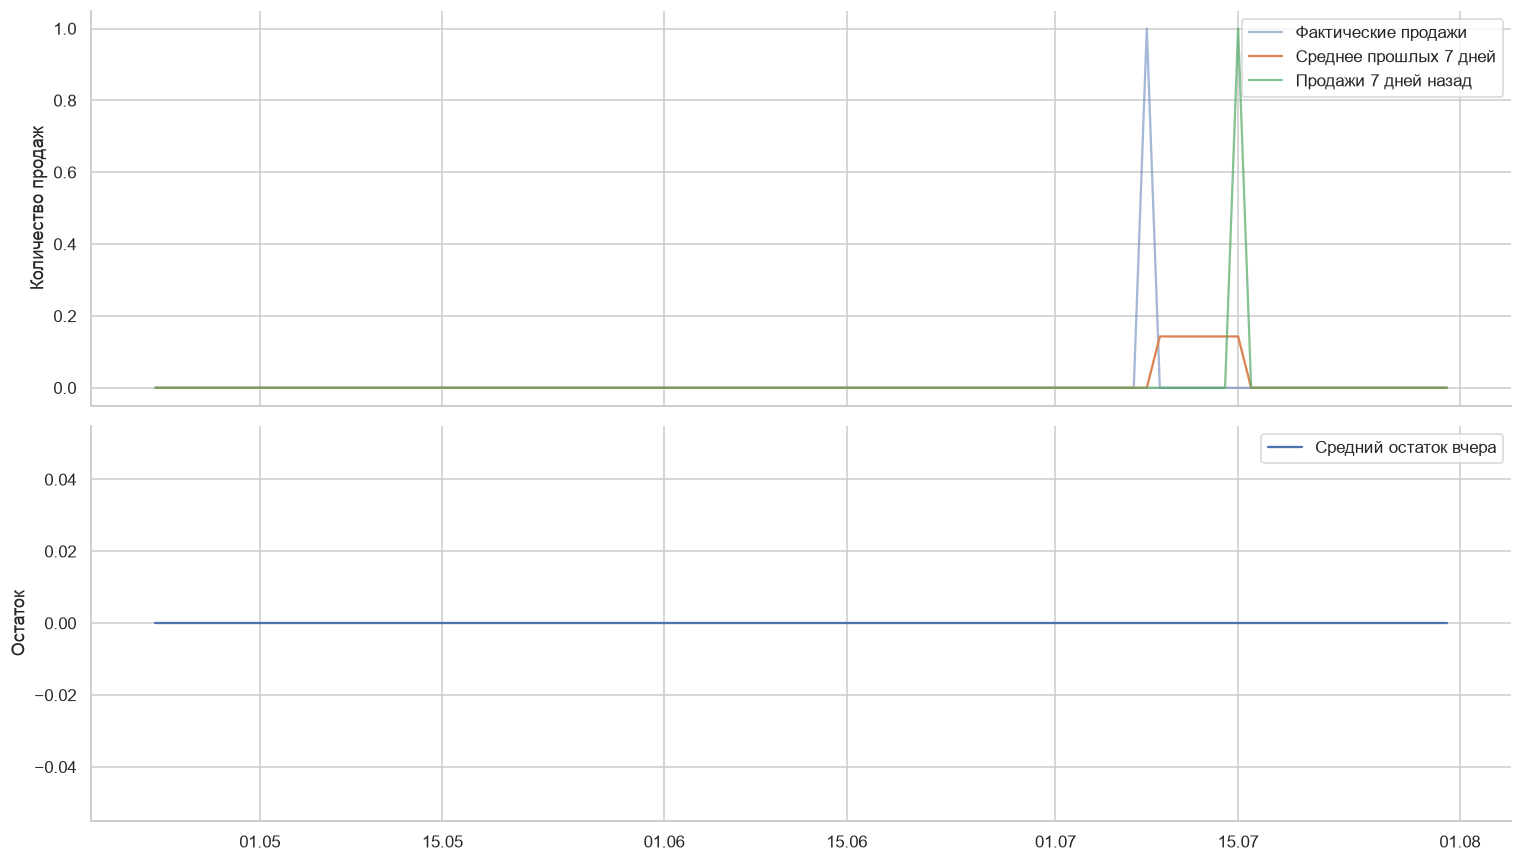

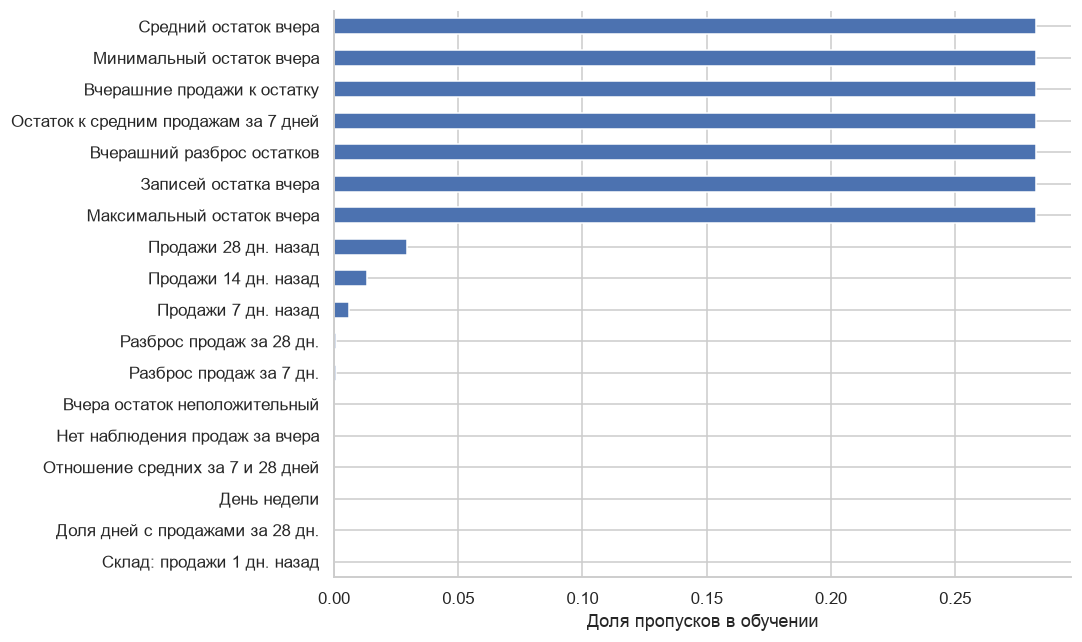

,Признаков,Максимальная доля пропусков
Группа,,
Исходные категории,5,0.000000
Явные сочетания категорий,3,0.000000
Календарь и возраст пары,13,0.000000
История продаж пары,14,0.029257
Остаток,9,0.282663
Продажи склада и артикула,6,0.000000


In [6]:
example=panel.loc[panel.pair_id.eq(example_id)].tail(100)
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
axes[0].plot(example.date,example.quantity,label='Фактические продажи',alpha=.5)
axes[0].plot(example.date,example.qty_roll_mean_7,label='Среднее прошлых 7 дней')
axes[0].plot(example.date,example.qty_lag_7,label='Продажи 7 дней назад',alpha=.7); axes[0].legend(); axes[0].set_ylabel('Количество продаж')
axes[1].plot(example.date,example.stock_mean_lag_1,label='Средний остаток вчера'); axes[1].legend(); axes[1].set_ylabel('Остаток')
plt.tight_layout(); plt.savefig(OUT/'01_feature_example.png',dpi=160,bbox_inches='tight'); plt.show()
missing=train[NUMERIC].isna().mean().sort_values(ascending=False)
missing.rename(index=feature_label).head(18).sort_values().plot.barh(figsize=(10,6)); plt.xlabel('Доля пропусков в обучении'); plt.tight_layout(); plt.savefig(OUT/'02_feature_missingness.png',dpi=160,bbox_inches='tight'); plt.show()
# Справочник для коллег: откуда берётся каждый признак и когда он доступен.
rows=[]
for group,cols in [('identity',CATEGORICAL),('crosses',CROSSES),*manifest['groups'].items()]:
    for col in cols:
        rows.append({'feature':col,'group':group,'available_by':'t-1' if group in ['history','stock','aggregate'] else 'forecast time',
                     'train_missing_share':float(train[col].isna().mean()),'train_unique':int(train[col].nunique())})
pd.DataFrame(rows).to_csv(OUT/'feature_dictionary.csv',index=False)
display_ru(pd.DataFrame(rows).groupby('group',sort=False).agg(features=('feature','size'),max_missing=('train_missing_share','max')))


## Распределения всех числовых FE-признаков

Графики рассчитаны на сохранённой train-выборке. Для читаемости ось X ограничена train-квантилями 0,1%–99,5%, частоты показаны в логарифмической шкале. Это ограничение касается только рисунка; исходные признаки не меняются. Полные статистики сохраняем в CSV.

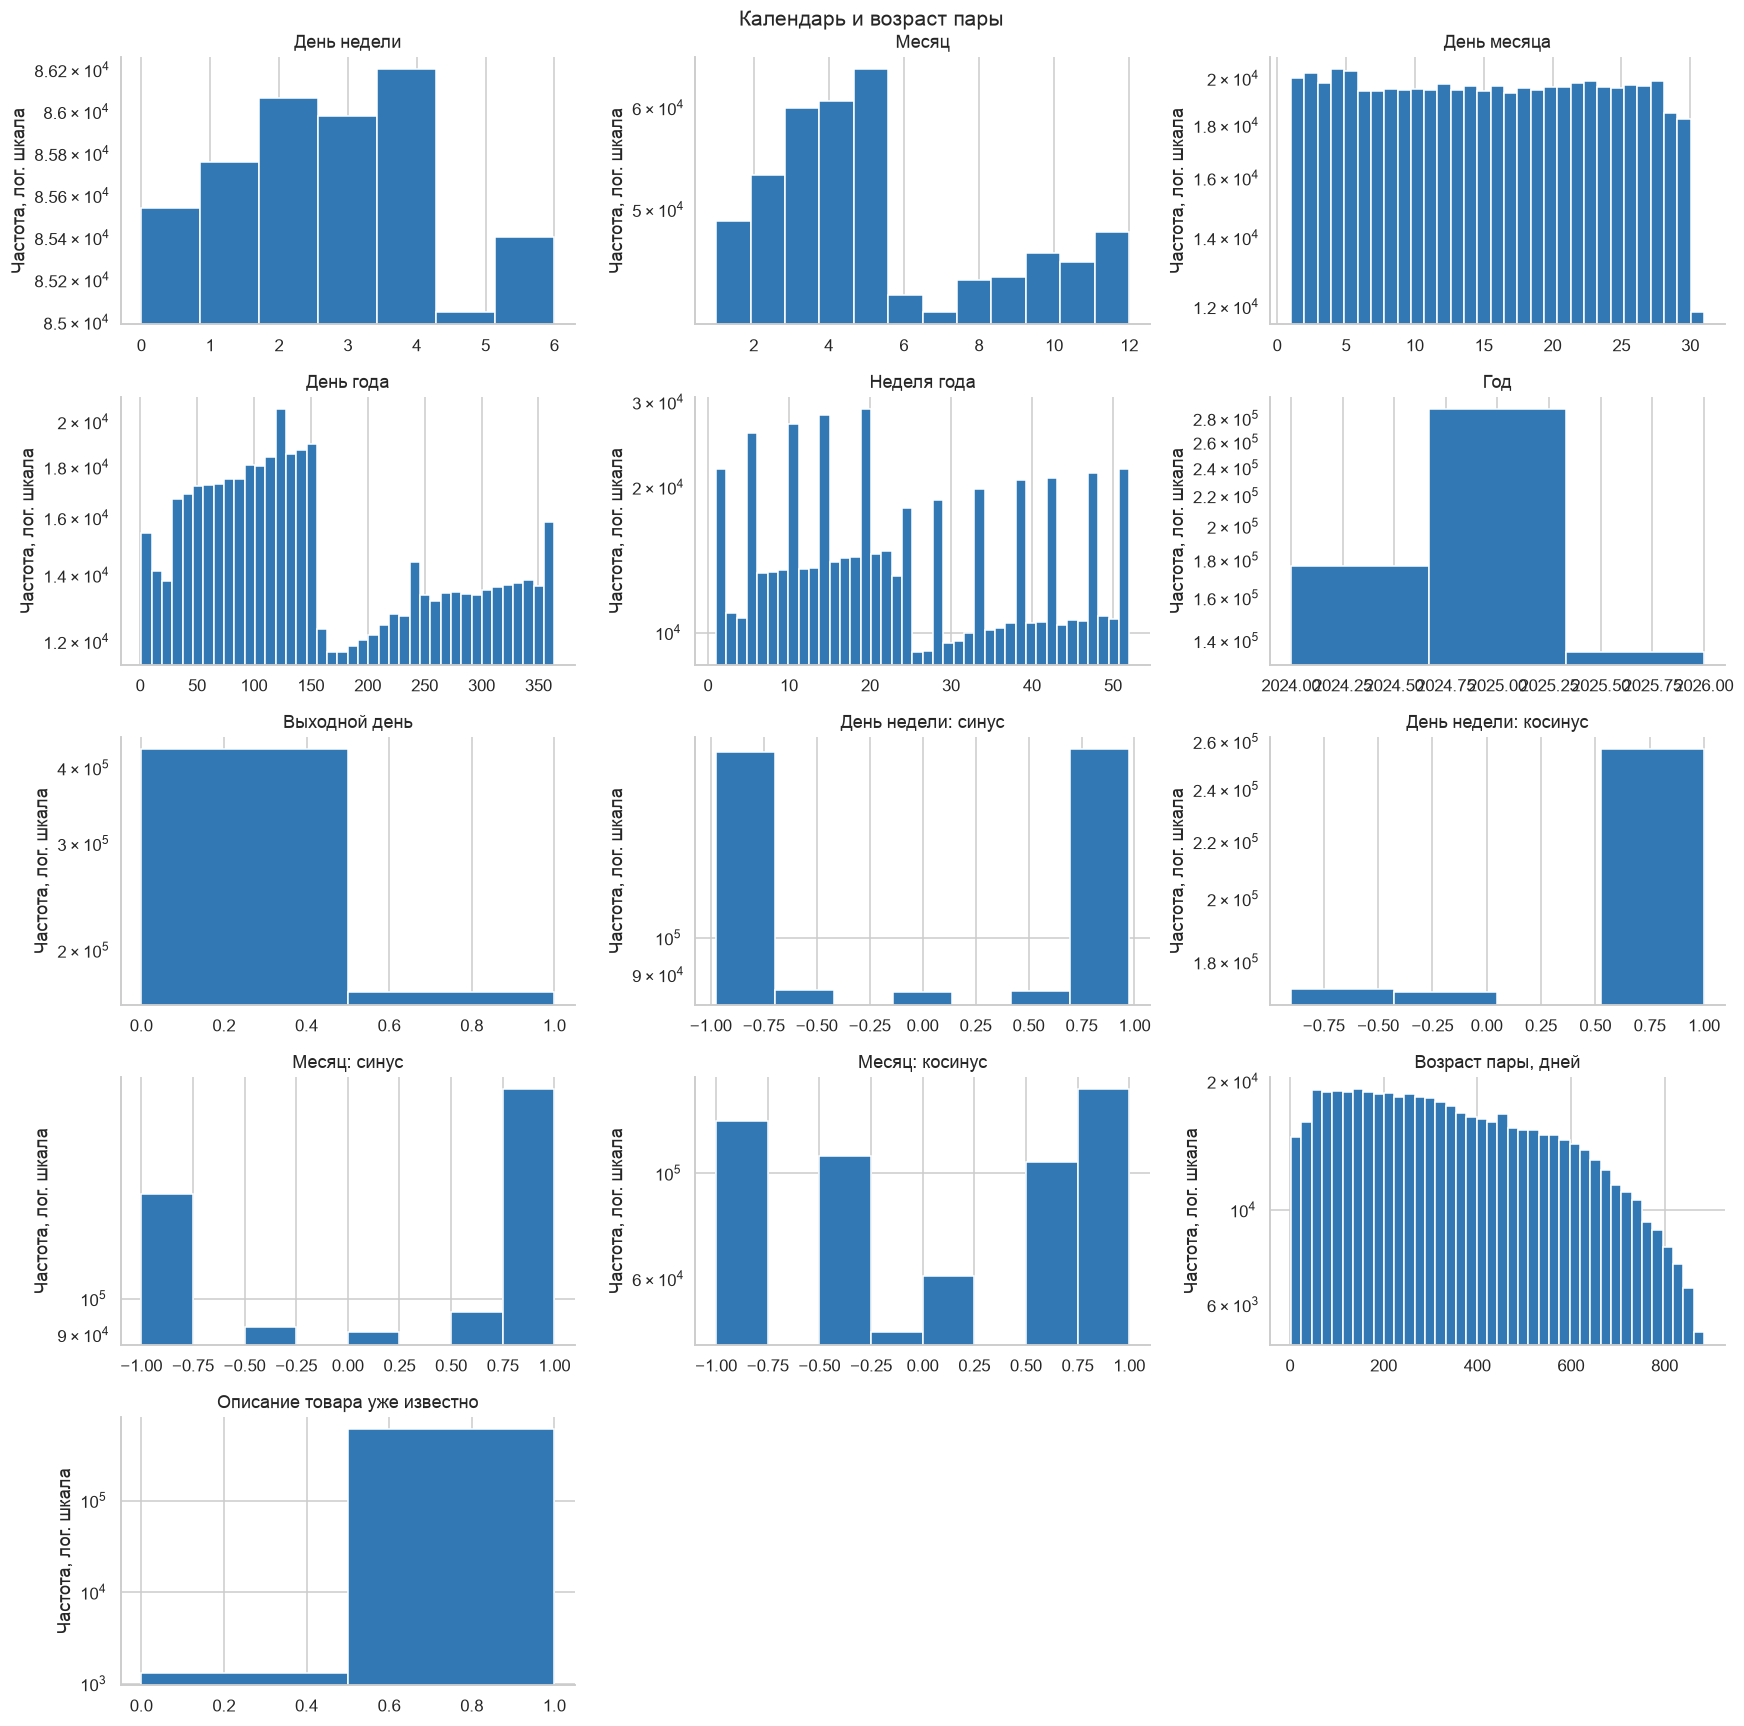

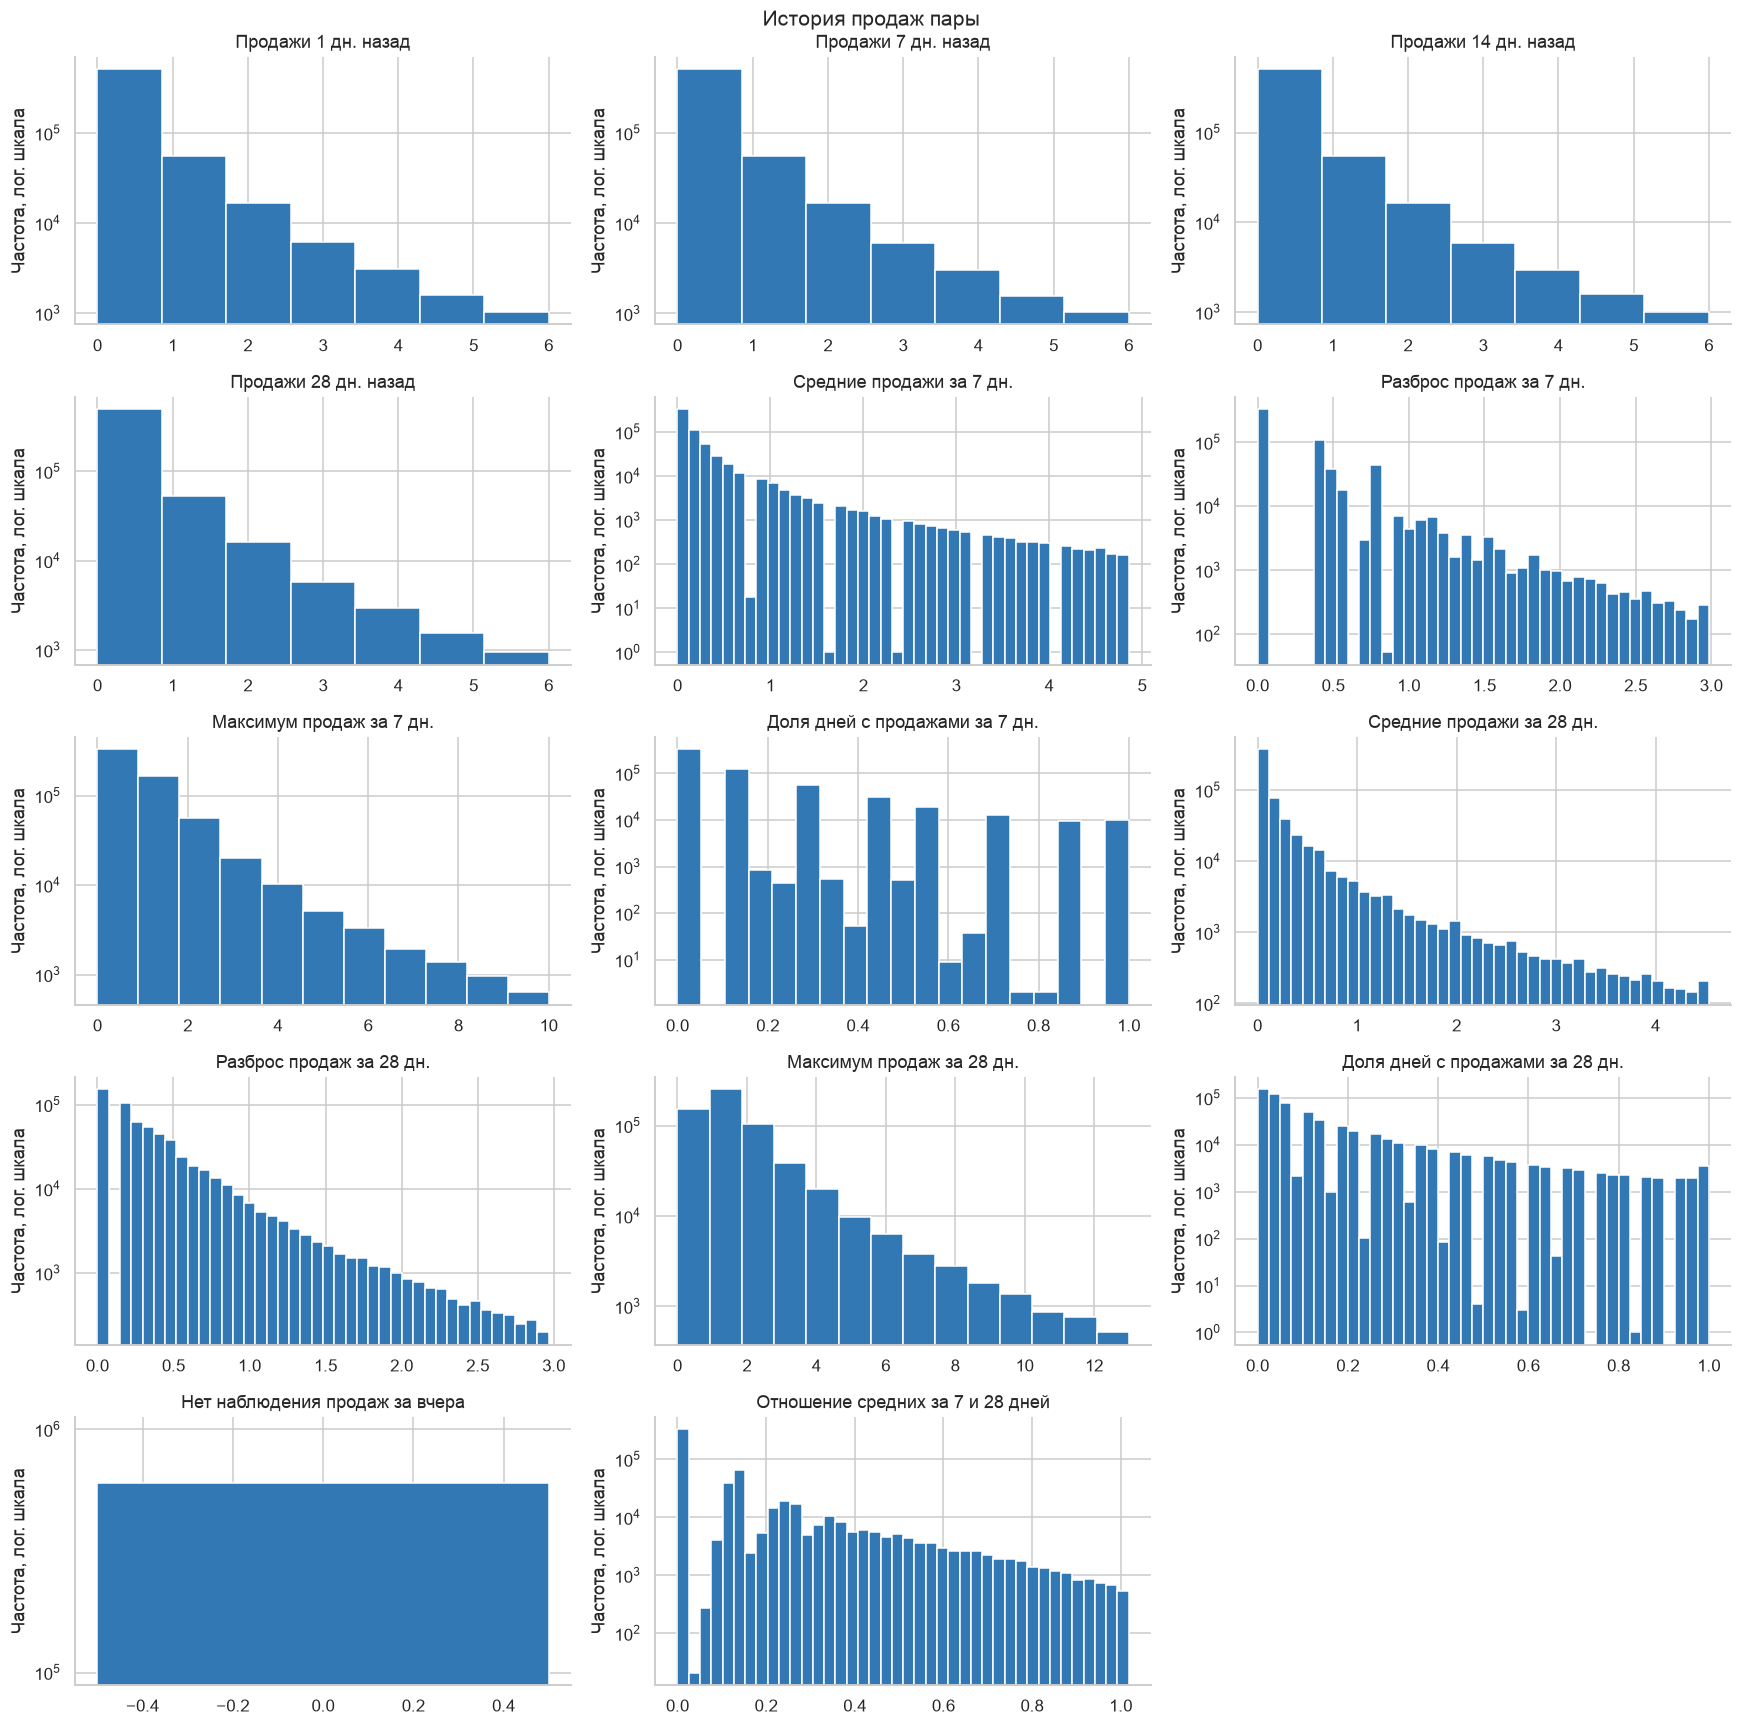

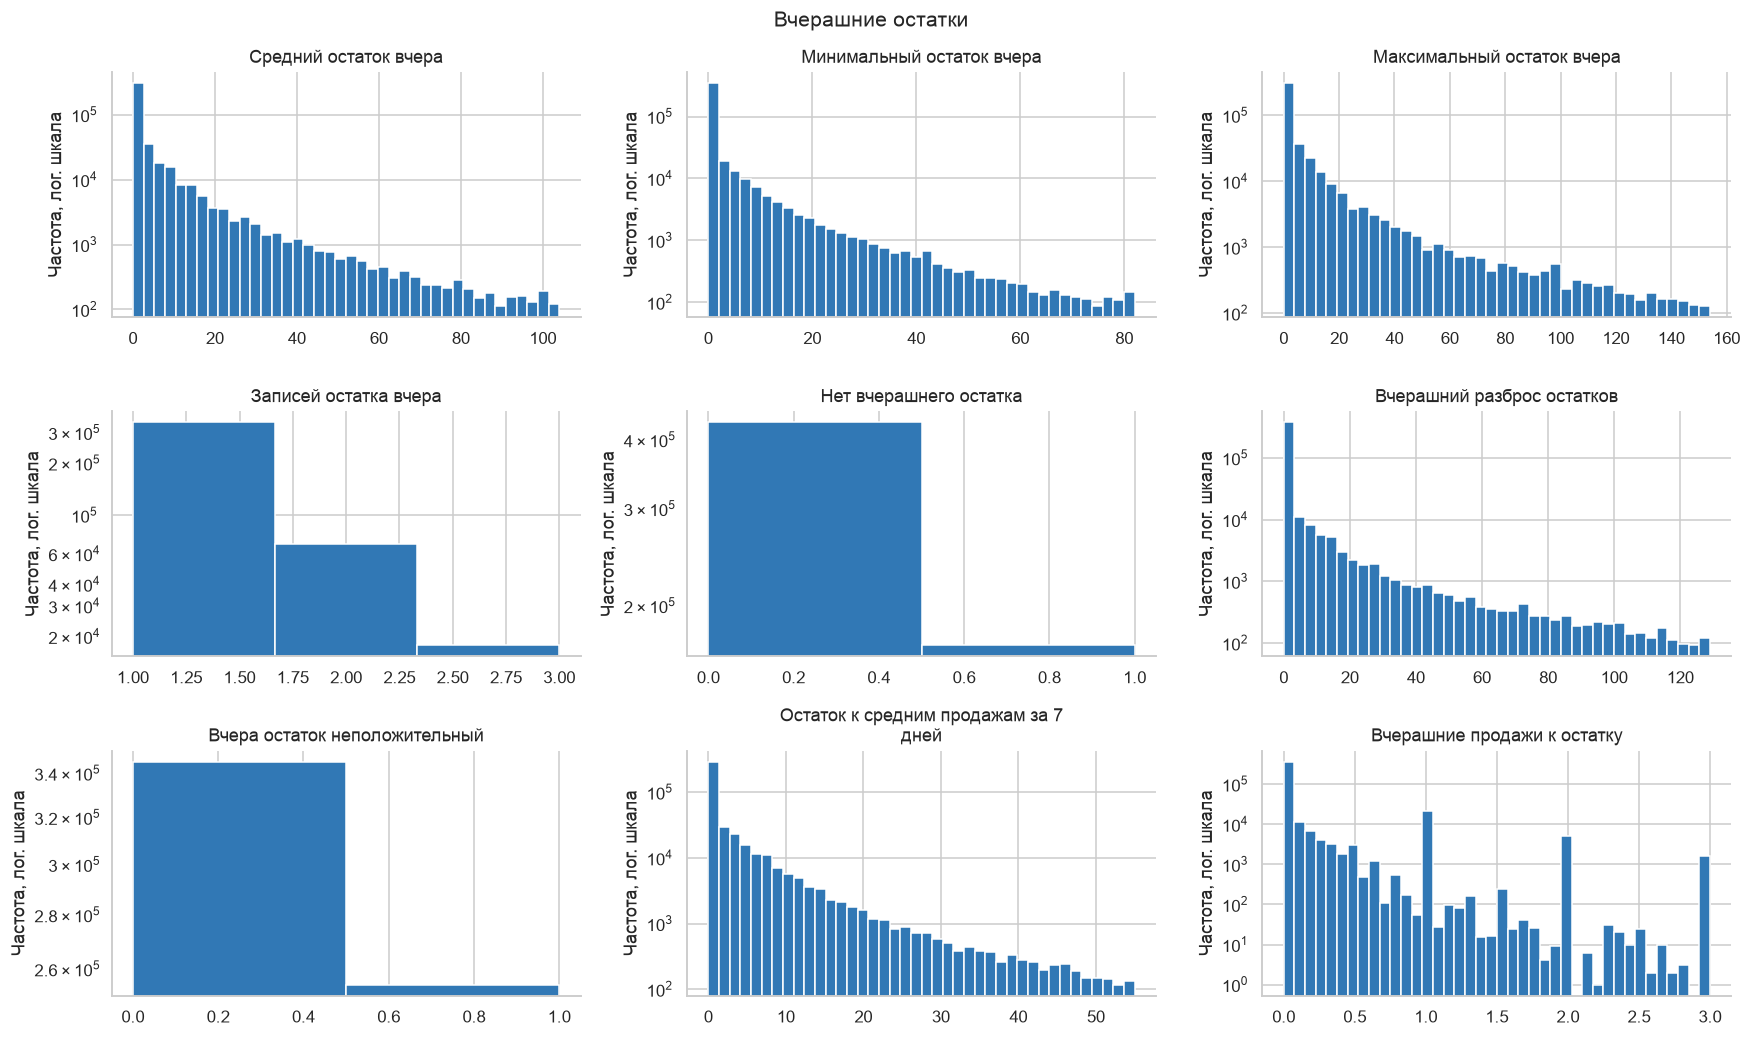

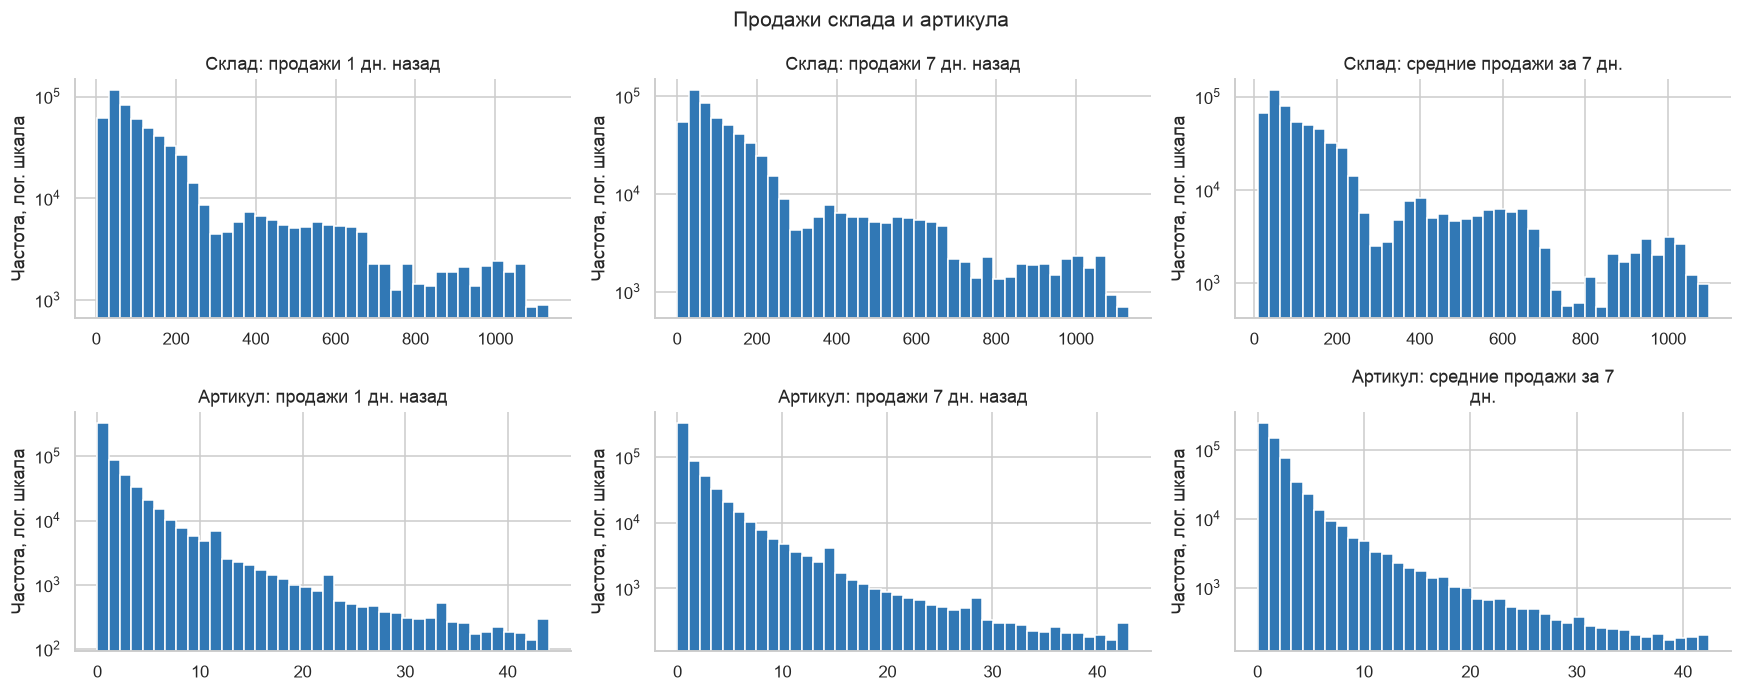

Полная панель: 6616681 строк; 8778 пар.
Изменение будущих продаж не меняет прошлые лаги и окна.


5659

In [7]:
feature_stats=train[NUMERIC].describe(percentiles=[.001,.01,.5,.99,.995,.999]).T
feature_stats['missing_share']=train[NUMERIC].isna().mean()
feature_stats.to_csv(OUT/'numeric_feature_profile.csv')
for group,columns in manifest['groups'].items():
    ncols=3; nrows=(len(columns)+ncols-1)//ncols
    fig,axes=plt.subplots(nrows,ncols,figsize=(16,3.2*nrows),squeeze=False)
    for ax,col in zip(axes.ravel(),columns):
        values=train[col].dropna(); lo,hi=values.quantile([.001,.995])
        central=values[values.between(lo,hi)]
        ax.hist(central,bins=min(40,max(1,central.nunique())),log=True,color='#3178b5')
        ax.set(title=feature_label(col, width=32),ylabel='Частота, лог. шкала')
    for ax in axes.ravel()[len(columns):]: ax.set_visible(False)
    fig.suptitle(GROUP_LABELS[group],fontsize=14); plt.tight_layout()
    plt.savefig(OUT/f'03_distributions_{group}.png',dpi=160,bbox_inches='tight'); plt.show()
print('Полная панель:',manifest['panel_rows'],'строк;',manifest['pairs'],'пар.')
# Проверка отсутствия зависимости прошлых лагов от будущих продаж.
q=check.quantity.reset_index(drop=True).copy()
mutated=q.copy(); cutoff=len(q)//2; mutated.iloc[cutoff:]=100000
for lag in [1,7,14,28]:
    np.testing.assert_allclose(q.shift(lag).iloc[:cutoff+1],mutated.shift(lag).iloc[:cutoff+1],equal_nan=True)
for window in [7,28]:
    np.testing.assert_allclose(q.shift(1).rolling(window,min_periods=1).mean().iloc[:cutoff+1],
                               mutated.shift(1).rolling(window,min_periods=1).mean().iloc[:cutoff+1],equal_nan=True)
print('Изменение будущих продаж не меняет прошлые лаги и окна.')
del panel,stock_daily,sales_daily,train,valid,test
import gc; gc.collect()

## Ограничения первой итерации

`quantity` — наблюдаемые продажи, а не скрытый спрос при отсутствии товара. Нулевые дни и агрегация остатков основаны на допущениях. Годовые праздники и внешние источники пока не добавляли. Полный train в моделях заменён фиксированной выборкой ради скорости первой итерации; валидация и тест не сэмплируются.

Дальше сравниваем сезонный наивный прогноз, среднее за 7 дней, линейную модель, CatBoost и DCN на одинаковых строках. Официальная метрика неизвестна: основная локальная метрика — MAE, дополнительно WAPE, RMSE и RMSLE.